# Heyert Notebook
### 2026-11
### Text Corpus Exploration | Project 03 | NLP

Exploratory analysis of job application messages using token frequencies, category comparisons, context windows, bigrams, and a token-frequency visualization.

**Data requirement:** Place your csv corpus in the project’s local `data/` directory. The data directory is excluded from version control, for privacy reasons and this notebook does not embed the dataset. This pipeline should be adaptable to any CSV with a category column and a text column.

## 1. Imports and project paths

The project root is found by locating `pyproject.toml` in the current directory or one of the parents to resolve common path errors in Jupyter Notebooks.

In [286]:
from pathlib import Path

from IPython.display import display  # Fix linting issues
import matplotlib.pyplot as plt
import polars as pl

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not find the project root (pyproject.toml) from the current directory."
    )

data_file = project_root / "data" / "job_messages.csv"
if not data_file.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {data_file}. Add job_messages.csv to the project's data/ directory."
    )

print(f"Project root: {project_root}")
print(f"Dataset: {data_file}")
# Define the output path for saving figures
PLOT_PATH = project_root / "docs/images"
print(f"Plot path: {PLOT_PATH}")
ARTIFACT_PATH: Path = project_root / "artifacts"
print(f"Artifact path: {ARTIFACT_PATH}")

Project root: c:\Repos\nlp-03-text-exploration-context
Dataset: c:\Repos\nlp-03-text-exploration-context\data\job_messages.csv
Plot path: c:\Repos\nlp-03-text-exploration-context\docs\images
Artifact path: c:\Repos\nlp-03-text-exploration-context\artifacts


## 2. Load the corpus

Each row is treated as a document with a category and message text. The summary below reports dataset structure without displaying message contents.

In [287]:
df_corpus: pl.DataFrame = pl.read_csv(
    data_file, columns=["category", "text"]
).with_row_index("message_id")

print(f"Corpus contains {df_corpus.height} documents.")
print("Documents by category:")
display(df_corpus.group_by("category").len().sort("category"))

Corpus contains 202 documents.
Documents by category:


category,len
str,u64
"""application_received""",115
"""application_update""",5
"""interview_stage""",27
"""job_offer""",5
"""process_update""",16
"""rejected""",34


## 3. Tokenize and clean text - one version with stop words, one without

This simple tokenizer lowercases text, splits on whitespace, removes every character that is not a Unicode letter or number, and excludes tokens of two characters or fewer. For example, `don't` becomes `dont`, and `job-related` becomes `jobrelated` because punctuation is removed rather than replaced with a space. `token_df` contains the resulting tokens before stop-word filtering; `filtered_df` removes the words in `stop_words`.

### Where stop-word filtering is used

- **Uses `filtered_df`:** the overall token-frequency count and the token frequencies by category. This view omits the listed stop words.
- **Uses `token_df` (not stop-word filtered):** co-occurrence, and bigram frequencies and charts. These analyses keep stop words so category counts and word relationships reflect the original token sequence.

Filtering happens after tokenization. It does not change the token sequence used to calculate contexts or bigrams.

In [288]:
token_df: pl.DataFrame = (
    df_corpus.select(
        "message_id",
        "category",
        pl.col("text")
        .str.to_lowercase()
        .str.replace_all(r"\s+", " ")
        .str.strip_chars()
        .str.split(" ")
        .alias("token"),
    )
    .explode("token")
    .with_columns(pl.col("token").str.replace_all(r"[^\p{L}\p{N}]", "").alias("token"))
    .filter(pl.col("token") != "")
    .filter(pl.col("token").str.len_chars() > 2)
    .with_columns(pl.int_range(pl.len()).over("message_id").alias("position"))
    .sort(["message_id", "position"])
)

print(f"Tokenization produced {token_df.height} tokens.")
display(token_df.head(10))

Tokenization produced 19782 tokens.


message_id,category,token,position
u64,str,str,i64
0,"""application_received""","""thank""",0
0,"""application_received""","""you""",1
0,"""application_received""","""for""",2
0,"""application_received""","""your""",3
0,"""application_received""","""interest""",4
0,"""application_received""","""career""",5
0,"""application_received""","""oracle""",6
0,"""application_received""","""appreciate""",7
0,"""application_received""","""you""",8


In [289]:
stop_words = [
    "the",
    "a",
    "an",
    "and",
    "or",
    "but",
    "in",
    "on",
    "at",
    "to",
    "for",
    "of",
    "with",
    "by",
    "is",
    "are",
    "was",
    "were",
    "be",
    "been",
    "being",
    "have",
    "has",
    "had",
    "do",
    "does",
    "did",
    "will",
    "would",
    "can",
    "could",
    "should",
    "may",
    "might",
    "must",
    "shall",
    "your",
    "you",
]
filtered_df = token_df.filter(~pl.col("token").is_in(stop_words))
# Show the filtered DataFrame
display(filtered_df.head(5))

message_id,category,token,position
u64,str,str,i64
0,"""application_received""","""thank""",0
0,"""application_received""","""interest""",4
0,"""application_received""","""career""",5
0,"""application_received""","""oracle""",6
0,"""application_received""","""appreciate""",7


## 4. Global token frequencies

Count each token across the complete corpus, without stop words.

In [290]:
global_freq_df: pl.DataFrame = (
    filtered_df.group_by("token").len().sort("len", descending=True)
)
display(global_freq_df.head(10))

token,len
str,u64
"""our""",319
"""application""",275
"""this""",258
"""thank""",218
"""that""",169
"""team""",155
"""please""",147
"""interest""",146
"""position""",145


## 5. Token frequencies by category

Compare unfiltered token counts within each message category and collect the ten most frequent tokens in each. Stop words are retained here; only the overall token-frequency count above excludes stop words.

In [291]:
category_freq_df: pl.DataFrame = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len", "token"], descending=[False, True, False])
)
display(category_freq_df[:10])

category,token,len
str,str,u64
"""application_received""","""you""",506
"""application_received""","""your""",490
"""application_received""","""the""",438
"""application_received""","""and""",371
"""application_received""","""for""",366
"""application_received""","""our""",233
"""application_received""","""application""",203
"""application_received""","""will""",158
"""application_received""","""with""",132


## 6. Token co-occurrence

A word co-occurs with another when it appears immediately before or after it in the same message. Both tables use all tokens, including stop words, and sort co-occurring word pairs by frequency.

In [292]:
context_df = pl.concat(
    [
        token_df.select(
            "category",
            pl.col("token").alias("target_token"),
            pl.col("token").shift(offset).over("message_id").alias("context_token"),
        )
        for offset in [-1, 1]
    ]
).filter(
    pl.col("context_token").is_not_null()
    & (pl.col("target_token") != pl.col("context_token"))
)

co_occurrence_df = (
    context_df.group_by(["target_token", "context_token"])
    .len()
    .sort("len", descending=True)
)
display(co_occurrence_df.sort("len", descending=True).head(10))

co_occurrence_by_category_df = context_df.group_by(
    ["category", "target_token", "context_token"]
).len()
display(co_occurrence_by_category_df.sort("len", descending=True).head(10))

target_token,context_token,len
str,str,u64
"""you""","""thank""",221
"""thank""","""you""",221
"""your""","""application""",201
"""application""","""your""",201
"""for""","""you""",178
"""you""","""for""",178
"""for""","""your""",136
"""your""","""for""",136
"""your""","""interest""",132


category,target_token,context_token,len
str,str,str,u64
"""application_received""","""application""","""your""",146
"""application_received""","""your""","""application""",146
"""application_received""","""thank""","""you""",129
"""application_received""","""you""","""thank""",129
"""application_received""","""for""","""you""",106
"""application_received""","""you""","""for""",106
"""application_received""","""your""","""for""",74
"""application_received""","""for""","""your""",74
"""application_received""","""interest""","""your""",71


## 7. Bigram frequencies

A bigram is a pair of consecutive tokens from the same message. The token table is already sorted by message and position, so a grouped `shift(-1)` selects the next word without crossing message boundaries.

In [293]:
bigram_df: pl.DataFrame = (
    token_df.with_columns(
        pl.col("token").shift(-1).over("message_id").alias("next_token")
    )
    .filter(pl.col("next_token").is_not_null())
    .with_columns(pl.concat_str(["token", "next_token"], separator=" ").alias("bigram"))
    .select("message_id", "category", "bigram")
)

display(bigram_df.group_by("bigram").len().sort("len", descending=True).head(10))

bigram,len
str,u64
"""thank you""",218
"""your application""",196
"""you for""",160
"""for your""",136
"""your interest""",132
"""for the""",105
"""this email""",71
"""you can""",61
"""application for""",54


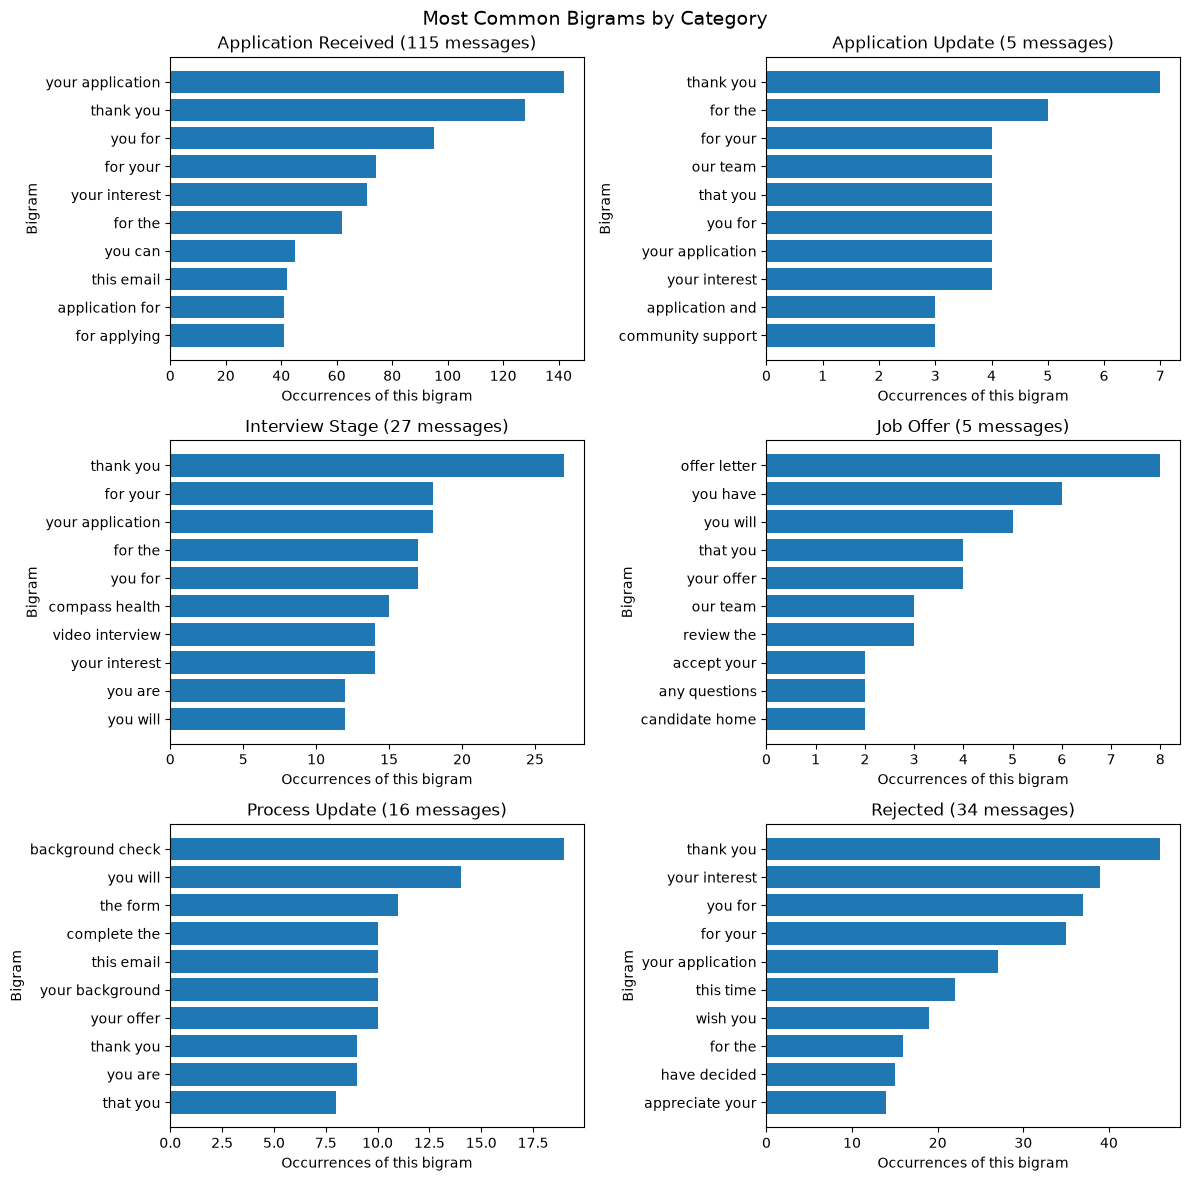

In [294]:
## 7a. Visualize Bigrams Per Category


categories = bigram_df["category"].unique().sort().to_list()
columns = 2
rows = (len(categories) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)
for ax, category in zip(axes.flat, categories):
    plot_df = (
        bigram_df.filter(pl.col("category") == category)
        .group_by("bigram")
        .len()
        .sort(["len", "bigram"], descending=[True, False])
        .head(10)
        .sort("len")
    )
    ax.barh(plot_df["bigram"].to_list(), plot_df["len"].to_list())
    number_of_messages = df_corpus.filter(pl.col("category") == category).height
    ax.set_title(
        f"{category.replace('_', ' ').title()} ({number_of_messages} messages)"
    )
    ax.set_xlabel("Occurrences of this bigram")
    ax.set_ylabel("Bigram")
for ax in axes.flat[len(categories) :]:
    ax.set_visible(False)
fig.suptitle("Most Common Bigrams by Category", fontsize=14)
fig.tight_layout()
plt.savefig(PLOT_PATH / "bigram_comparison.png")
plt.show()

## 8. Visualize category token frequencies

Plot the ten most frequent tokens in each category. Stop words are included.

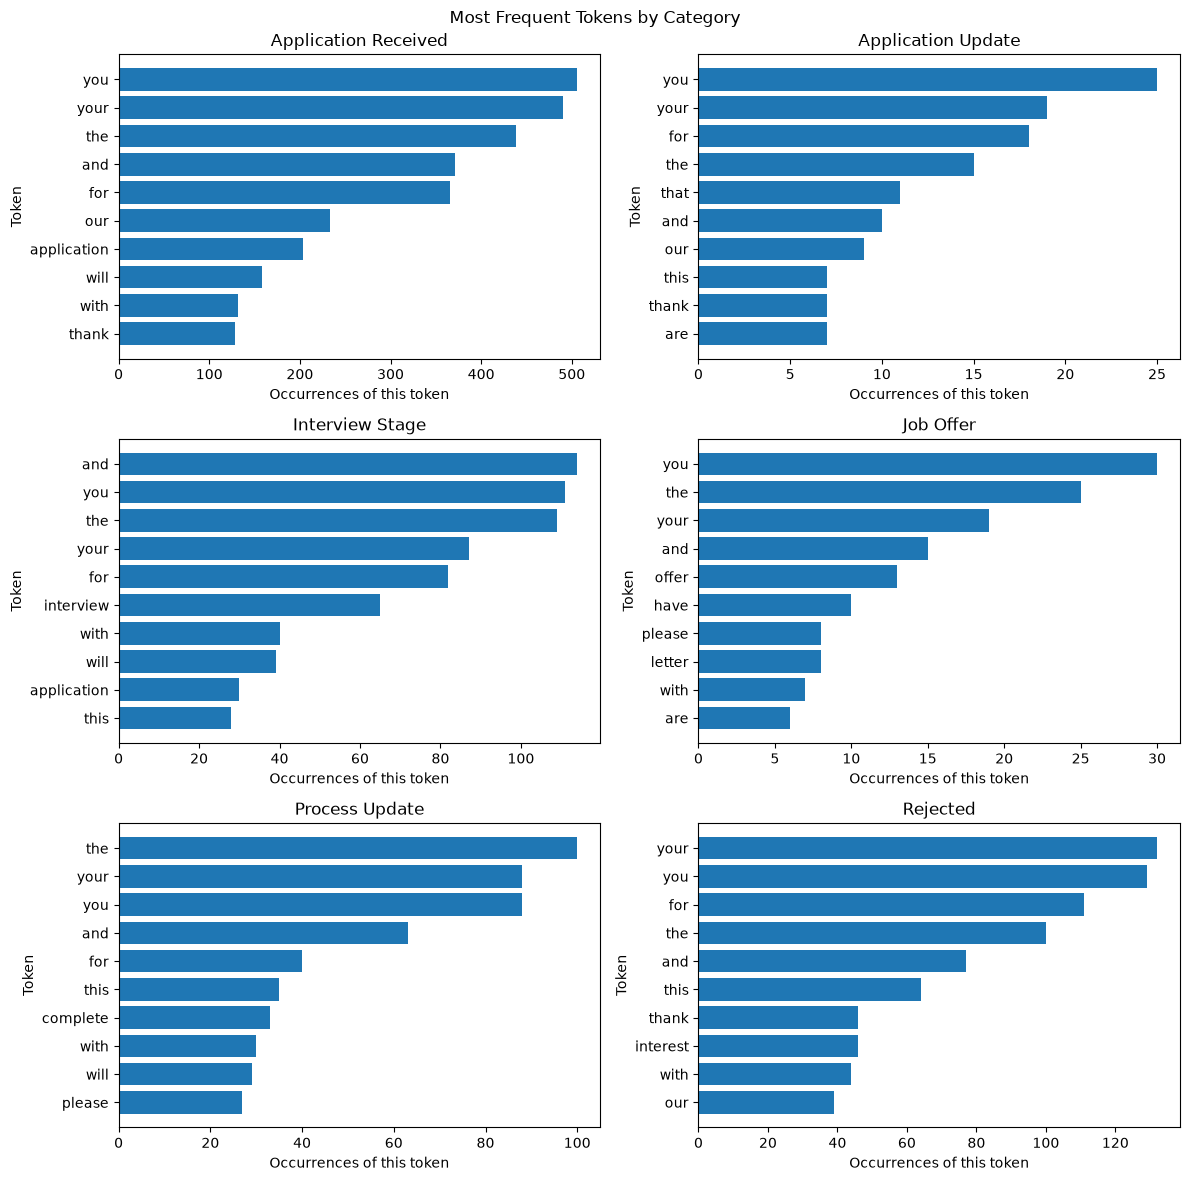

In [295]:
categories = category_freq_df["category"].unique().sort().to_list()
columns = 2
rows = (len(categories) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)
for ax, category in zip(axes.flat, categories):
    plot_df = (
        category_freq_df.filter(pl.col("category") == category).head(10).sort("len")
    )
    ax.barh(plot_df["token"].to_list(), plot_df["len"].to_list())
    ax.set_title(category.replace("_", " ").title())
    ax.set_xlabel("Occurrences of this token")
    ax.set_ylabel("Token")
for ax in axes.flat[len(categories) :]:
    ax.set_visible(False)
fig.suptitle("Most Frequent Tokens by Category")
fig.tight_layout()
plt.savefig(PLOT_PATH / "tokens_by_category.png")
plt.show()

## 9. Interpret the results

Add corpus-specific observations after reviewing the frequency tables, context examples, and visualization.

**TODO:** Describe notable patterns, differences between categories, limitations of the simple tokenizer, and questions for further analysis.